count    48.000000
mean      1.099267
std       0.299240
min       0.276488
25%       0.966099
50%       1.123024
75%       1.280010
max       1.901295
Name: Global_active_power, dtype: float64


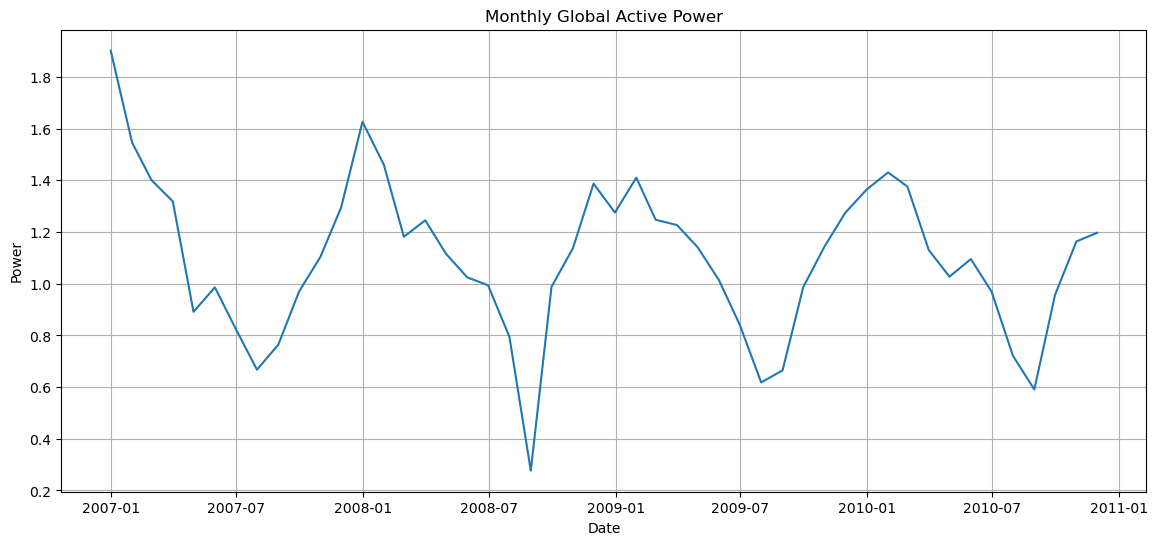

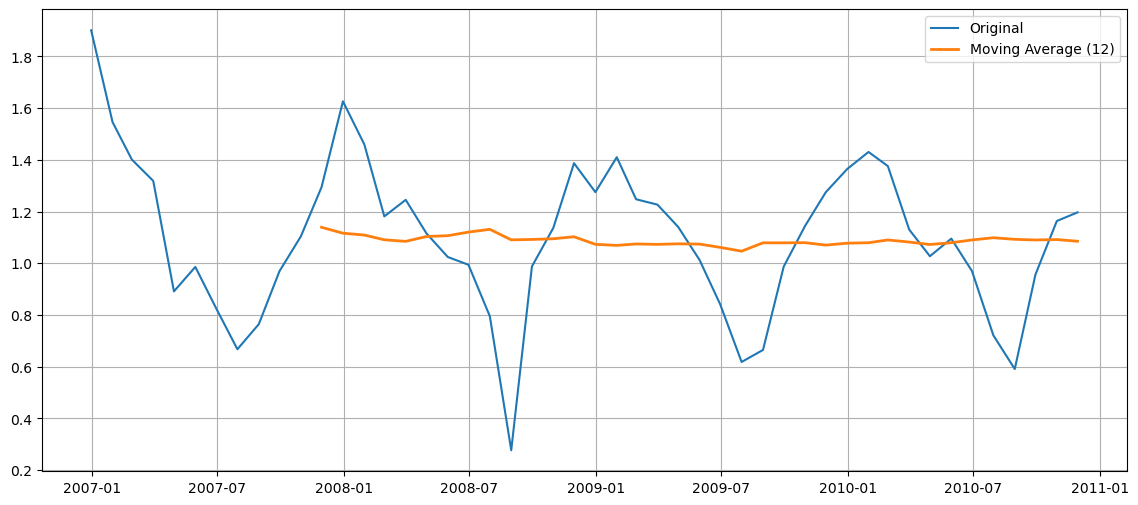

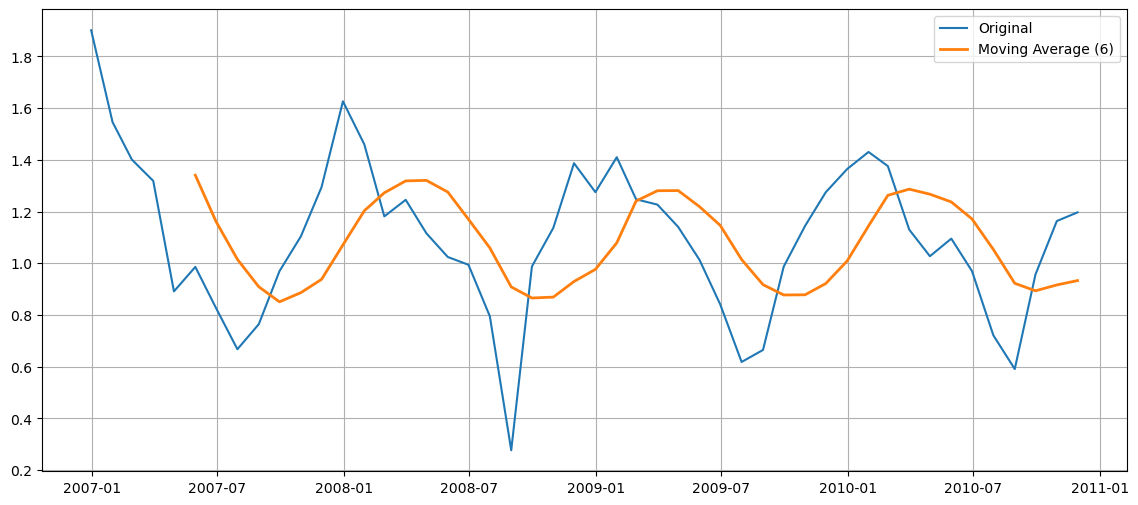

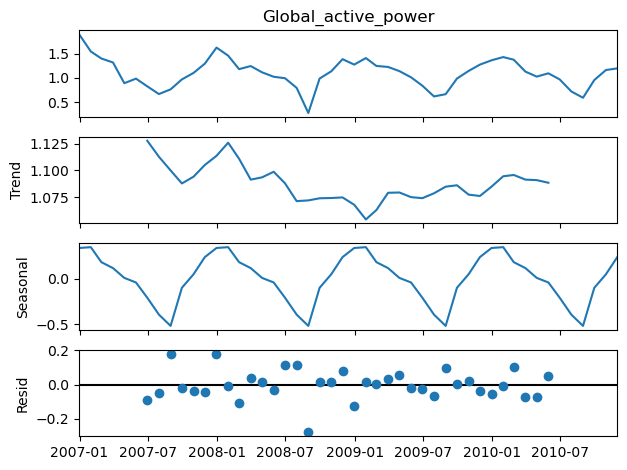

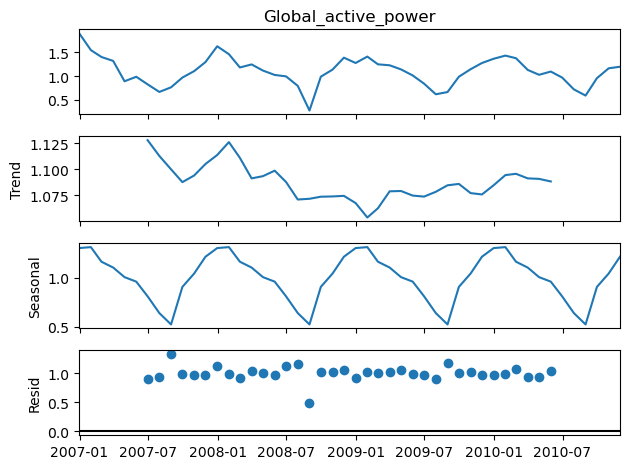

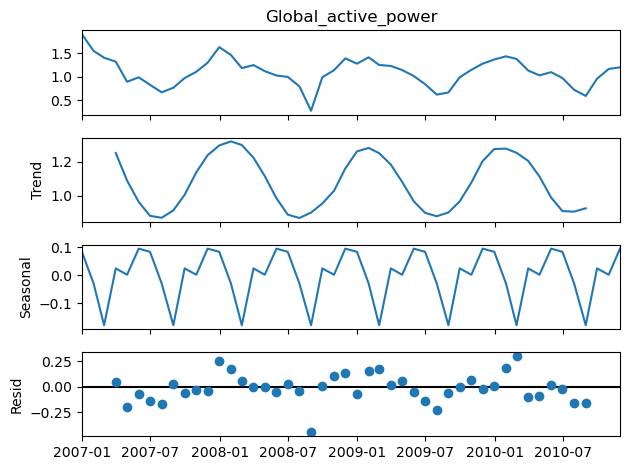

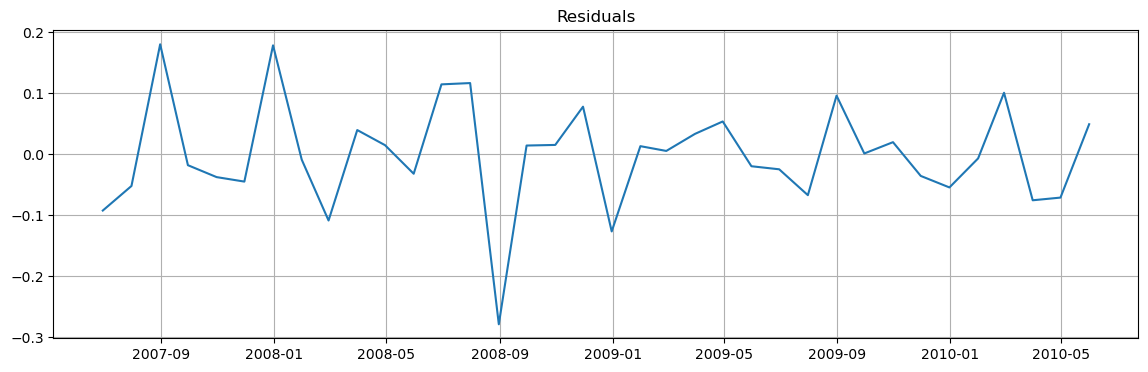

Datetime
2007-06-30    1.127729
2007-07-31    1.112690
2007-08-31    1.099948
2007-09-30    1.087740
2007-10-31    1.094052
Freq: ME, Name: trend, dtype: float64
Datetime
2006-12-31    0.334183
2007-01-31    0.342975
2007-02-28    0.179357
2007-03-31    0.114391
2007-04-30    0.007681
2007-05-31   -0.042302
2007-06-30   -0.208422
2007-07-31   -0.393161
2007-08-31   -0.516198
2007-09-30   -0.100380
2007-10-31    0.047457
2007-11-30    0.234419
Freq: ME, Name: seasonal, dtype: float64
count    36.000000
mean     -0.000877
std       0.087600
min      -0.279175
25%      -0.046764
50%      -0.002851
75%       0.042035
max       0.180436
Name: resid, dtype: float64


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values="?",
    low_memory=False
)

df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"],
    errors="coerce"
)

monthly = (
    df.set_index("Datetime")["Global_active_power"]
    .resample("ME")
    .mean()
    .dropna()
)

print(monthly.describe())

plt.figure(figsize=(14,6))
plt.plot(monthly)
plt.title("Monthly Global Active Power")
plt.xlabel("Date")
plt.ylabel("Power")
plt.grid(True)
plt.show()

ma12 = monthly.rolling(window=12).mean()

plt.figure(figsize=(14,6))
plt.plot(monthly,label="Original")
plt.plot(ma12,label="Moving Average (12)",linewidth=2)
plt.legend()
plt.grid(True)
plt.show()

ma6 = monthly.rolling(window=6).mean()

plt.figure(figsize=(14,6))
plt.plot(monthly,label="Original")
plt.plot(ma6,label="Moving Average (6)",linewidth=2)
plt.legend()
plt.grid(True)
plt.show()

additive = seasonal_decompose(
    monthly,
    model="additive",
    period=12
)

additive.plot()
plt.show()

multiplicative = seasonal_decompose(
    monthly,
    model="multiplicative",
    period=12
)

multiplicative.plot()
plt.show()

seasonal6 = seasonal_decompose(
    monthly,
    model="additive",
    period=6
)

seasonal6.plot()
plt.show()

plt.figure(figsize=(14,4))
plt.plot(additive.resid)
plt.title("Residuals")
plt.grid(True)
plt.show()

print(additive.trend.dropna().head())
print(additive.seasonal.head(12))
print(additive.resid.describe())

In [7]:
%pip install prophet

Note: you may need to restart the kernel to use updated packages.


بخش سوم

21:32:47 - cmdstanpy - INFO - Chain [1] start processing
21:33:23 - cmdstanpy - INFO - Chain [1] done processing


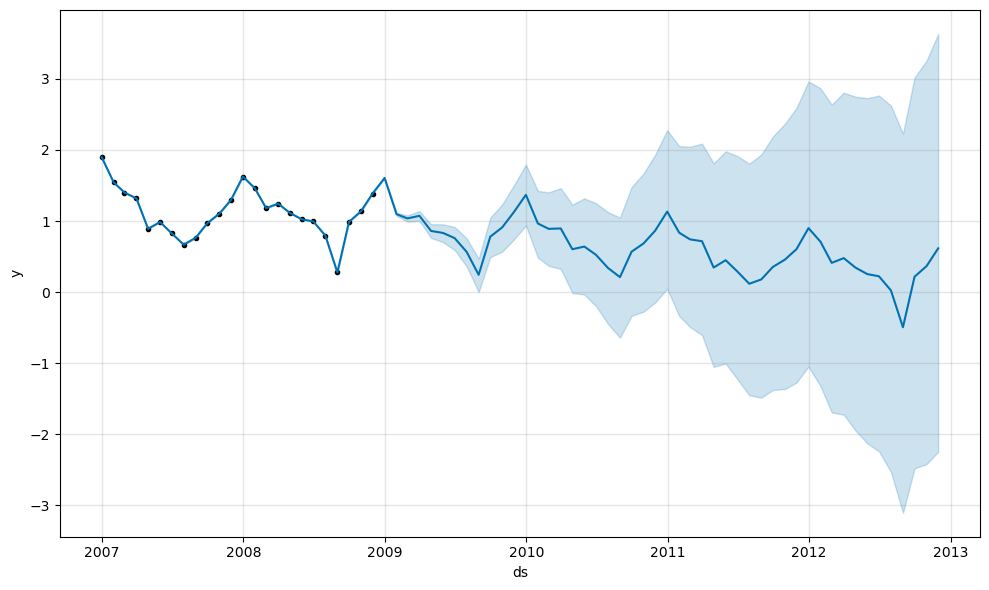

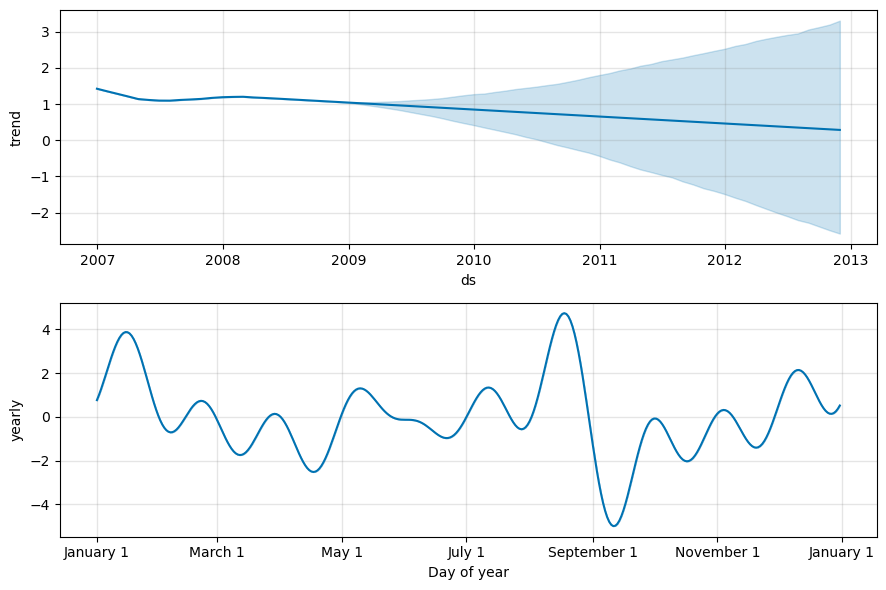

MAE: 0.2954
RMSE: 0.3271
MAPE: 29.13%


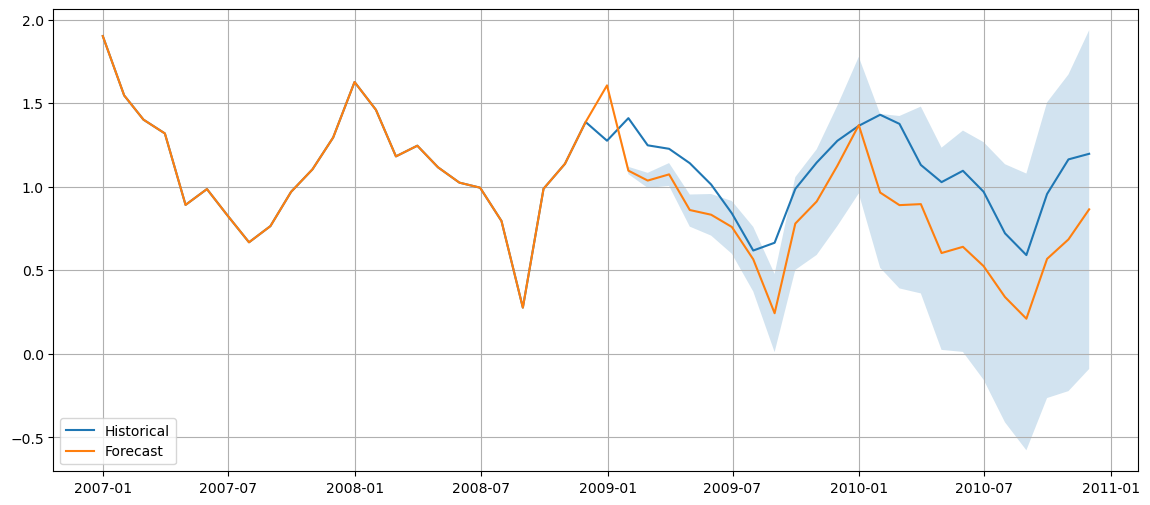

In [9]:
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

prophet_df = monthly.reset_index()
prophet_df.columns = ["ds", "y"]

train = prophet_df.iloc[:-24].copy()
test = prophet_df.iloc[-24:].copy()

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False
)

model.fit(train)

future = model.make_future_dataframe(periods=48, freq="ME")
forecast = model.predict(future)

fig = model.plot(forecast)
plt.grid(True)
plt.show()

fig2 = model.plot_components(forecast)
plt.show()

pred = (
    forecast.set_index("ds")
    .reindex(test["ds"])["yhat"]
    .to_numpy()
)

y_true = test["y"].to_numpy()

mae = mean_absolute_error(y_true, pred)
rmse = np.sqrt(mean_squared_error(y_true, pred))
mape = np.mean(np.abs((y_true - pred) / y_true)) * 100

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")

future24 = model.make_future_dataframe(periods=24, freq="ME")
forecast24 = model.predict(future24)

plt.figure(figsize=(14,6))
plt.plot(prophet_df["ds"], prophet_df["y"], label="Historical")
plt.plot(forecast24["ds"], forecast24["yhat"], label="Forecast")
plt.fill_between(
    forecast24["ds"],
    forecast24["yhat_lower"],
    forecast24["yhat_upper"],
    alpha=0.2
)
plt.legend()
plt.grid(True)
plt.show()

بخش امتیازی

C:\Users\Asus\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


SARIMA MAE = 0.12968623217593547
SARIMA RMSE = 0.16978966348953645
SARIMA MAPE = 13.882645473894693


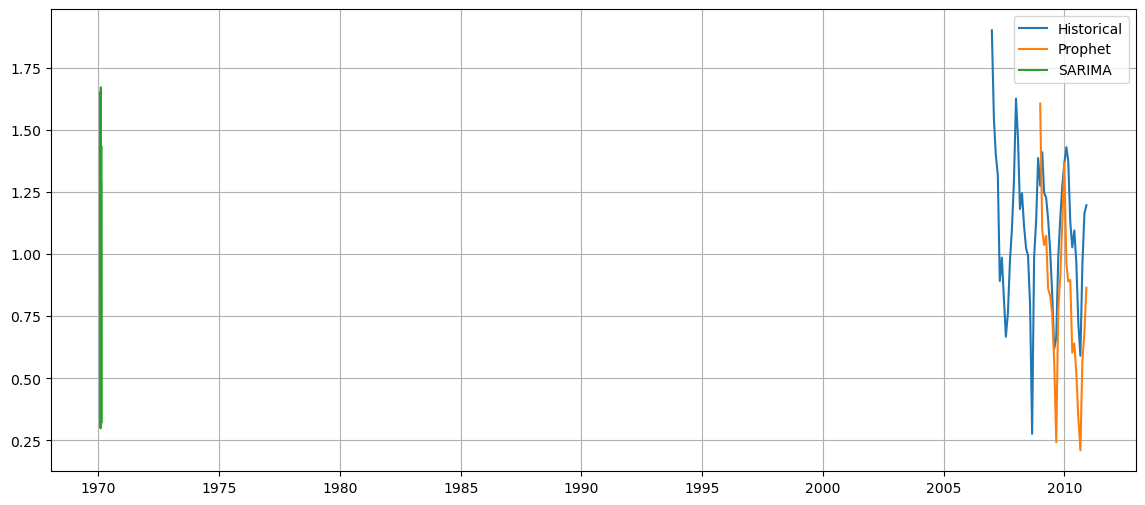

     Model       MAE     RMSE       MAPE
0  Prophet  0.295432  0.32708  29.131607
1   SARIMA  0.129686  0.16979  13.882645


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima = SARIMAX(
    train["y"],
    order=(1,1,1),
    seasonal_order=(1,1,1,12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima.fit(disp=False)

sarima_pred = sarima_fit.get_forecast(steps=24)

sarima_values = sarima_pred.predicted_mean.values

mae_sarima = mean_absolute_error(test["y"], sarima_values)
rmse_sarima = np.sqrt(mean_squared_error(test["y"], sarima_values))
mape_sarima = np.mean(np.abs((test["y"] - sarima_values) / test["y"])) * 100

print("SARIMA MAE =", mae_sarima)
print("SARIMA RMSE =", rmse_sarima)
print("SARIMA MAPE =", mape_sarima)

future_sarima = sarima_fit.get_forecast(steps=24)

plt.figure(figsize=(14,6))
plt.plot(monthly.index, monthly.values, label="Historical")
plt.plot(
    future24["ds"].tail(24),
    forecast24["yhat"].tail(24),
    label="Prophet"
)
plt.plot(
    test["ds"],
    future_sarima.predicted_mean.values,
    label="SARIMA"
)
plt.legend()
plt.grid(True)
plt.show()

comparison = pd.DataFrame({
    "Model":["Prophet","SARIMA"],
    "MAE":[mae,mae_sarima],
    "RMSE":[rmse,rmse_sarima],
    "MAPE":[mape,mape_sarima]
})

print(comparison)

